# 02 · Graph SLAM

Graph SLAM estimates every pose and every landmark at once, as the solution of one linear system.

**Constraints.** Each motion and each measurement relates two unknowns: "pose *i + 1* minus pose *i* equals the commanded move", or "landmark *j* minus pose *i* equals the measured offset". Each relation is a soft constraint `b − a = d` with a weight `w = 1 / noise`, so that more reliable sources pull harder.

**Information form.** A constraint adds a 2 × 2 pattern to the information matrix Ω and a pair of entries to the vector ξ, separately for x and y:

```
Ω[a,a] += w   Ω[b,b] += w   Ω[a,b] −= w   Ω[b,a] −= w
ξ[a]   −= d·w                ξ[b]   += d·w
```

The first pose is anchored at the known start with `Ω[0,0] = Ω[1,1] = 1`. Without that anchor the whole map could slide freely and Ω would be singular.

**Solution.** The best estimate (least squares, and maximum likelihood under Gaussian noise) is μ = Ω⁻¹ξ. `slam.slam` computes it with `np.linalg.solve(Ω, ξ)`, which gives the same result as forming the inverse, but is cheaper and numerically more stable.

The state uses an interleaved layout: `[x0, y0, x1, y1, …, Lx0, Ly0, …]`, so pose *i* is at indices `2i, 2i+1` and landmark *j* at `2(N+j), 2(N+j)+1`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable
ASSETS = Path.cwd().parent / "assets"

import matplotlib.pyplot as plt
import numpy as np

import metrics
import slam
import viz
import world
from data import udacity_test_cases as U

## One constraint at a time

A tiny system with 3 poses and 1 landmark, in a 10 × 10 world: the initial anchor, then one move of (+2, +1) and one measurement of the landmark at offset (+3, −1) from pose 0. The printed blocks are the x rows of Ω and ξ (x0, x1, x2, Lx0).

In [2]:
omega, xi = slam.initialize_constraints(N=3, num_landmarks=1, world_size=10.0)
slam.add_constraint(omega, xi, slam.pose_index(0), slam.pose_index(1), (2.0, 1.0), w=1.0)
slam.add_constraint(omega, xi, slam.pose_index(0), slam.landmark_index(0, 3), (3.0, -1.0), w=1.0)

x_rows = [0, 2, 4, 6]
print("Omega (x rows/cols):\n", omega[np.ix_(x_rows, x_rows)])
print("xi (x rows):", xi[x_rows].ravel())

Omega (x rows/cols):
 [[ 3. -1.  0. -1.]
 [-1.  1.  0.  0.]
 [ 0.  0.  0.  0.]
 [-1.  0.  0.  1.]]
xi (x rows): [0. 2. 0. 3.]


Pose 2 has no constraint yet: its row is all zeros, so this system cannot be solved until another move links it to the graph. In a full run every pose has at least one motion constraint, and every landmark at least one measurement.

## Structure of Ω on a real run

The same seed-0 run as in notebook 01: 20 poses, 5 landmarks. Ω is sparse. The pose block is tridiagonal, because motion only links consecutive poses, and the off-diagonal blocks mark which pose saw which landmark. Landmarks are never linked to each other directly.

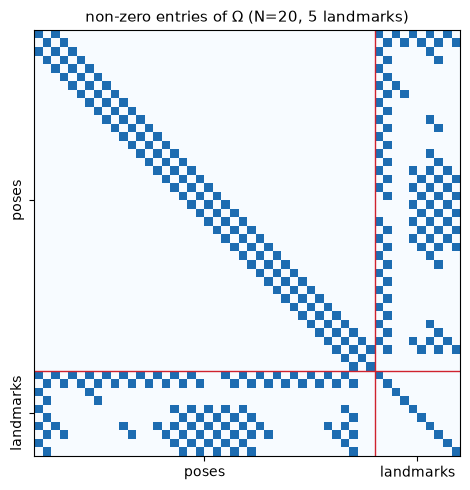

Omega: 50 x 50, 12% non-zero


In [3]:
sim = world.simulate_random(N=20, num_landmarks=5, seed=0)
omega, xi = slam.build_system(sim.data, sim.N, sim.num_landmarks, **sim.slam_args())

fig, ax = plt.subplots(figsize=(5, 5))
viz.plot_omega(ax, omega, sim.N, sim.num_landmarks, title="non-zero entries of Ω (N=20, 5 landmarks)")
fig.tight_layout()
fig.savefig(ASSETS / "omega_structure.png", dpi=120)
plt.show()
print("Omega: %d x %d, %.0f%% non-zero" % (*omega.shape, 100 * np.mean(omega != 0)))

## Running SLAM

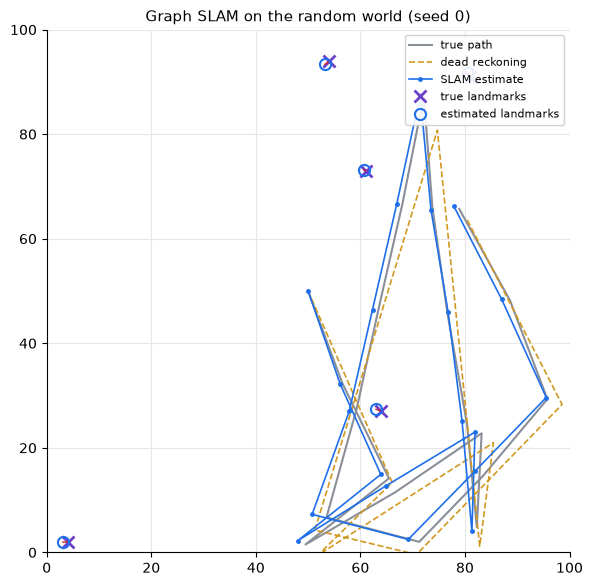

true final pose:      (78.912, 65.694)
estimated final pose: (77.900, 66.173)
landmark 0  true [64. 27.]  est (63.00, 27.35)  error 1.06  seen 18 times
landmark 1  true [4. 2.]  est (3.09, 1.95)  error 0.91  seen  2 times
landmark 2  true [81. 91.]  est (80.62, 91.68)  error 0.78  seen  7 times
landmark 3  true [61. 73.]  est (60.67, 73.20)  error 0.38  seen 12 times
landmark 4  true [54. 94.]  est (53.24, 93.36)  error 0.99  seen  7 times
final_pose_err     1.119
pose_rmse          1.442
landmark_rmse      0.859
dr_final_pose_err  2.287
dr_pose_rmse       3.724


In [4]:
mu = slam.slam(sim.data, sim.N, sim.num_landmarks, **sim.slam_args())
poses, landmarks = slam.unpack(mu, sim.N, sim.num_landmarks)
dr = metrics.dead_reckoning(sim.data, sim.start)

fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_world(ax, sim.world_size, true_poses=sim.true_poses, est_poses=poses, dr_poses=dr,
               true_landmarks=sim.landmarks, est_landmarks=landmarks,
               title="Graph SLAM on the random world (seed 0)")
fig.tight_layout()
fig.savefig(ASSETS / "slam_random.png", dpi=120)
plt.show()

print("true final pose:      (%.3f, %.3f)" % tuple(sim.true_poses[-1]))
print("estimated final pose: (%.3f, %.3f)" % tuple(poses[-1]))
counts = np.bincount([m[0] for z, _ in sim.data for m in z], minlength=sim.num_landmarks)
for j in range(sim.num_landmarks):
    print("landmark %d  true %s  est (%.2f, %.2f)  error %.2f  seen %2d times"
          % (j, sim.landmarks[j], *landmarks[j], np.linalg.norm(landmarks[j] - sim.landmarks[j]), counts[j]))
for k, v in metrics.evaluate(sim).items():
    print("%-18s %.3f" % (k, v))

## Why the estimate differs from the truth

The estimated final pose is 1.12 units from the true one, at (77.900, 66.173) against (78.912, 65.694). Over the whole path the error is 1.44 RMSE, compared with 3.72 for dead reckoning, so the measurements cut the path error to less than half.

The estimate cannot be exact. The solver never sees the true positions, only moves and measurements that are each off by up to ±2 units per axis. It returns the configuration that best agrees with all of them at once. Where the constraints disagree, it splits the difference according to their weights, and the result inherits part of every error.

Landmarks are estimated better than poses (0.86 RMSE) because each one is measured from several poses, and independent errors partly cancel out. The observation count is not the whole story, though. Landmark 3, seen 12 times, is the most accurate (0.38), but landmark 0, seen 18 times, is off by 1.06, about as much as landmark 1, seen only twice (0.91). A landmark's estimate also inherits the errors of the poses it was measured from.

Notebook 05 measures these effects systematically over 20 seeds. Errors grow linearly with the noise amplitude. Adding poses (larger N) keeps the pose error constant and reduces the landmark error, because every extra pass re-observes the same landmarks.

## Reference test cases

The course provides two recorded runs with expected outputs (`data/udacity_test_cases.py`: N = 20, 5 landmarks, noise 2.0). This implementation reproduces their shape, but not the published numbers to three decimals.

In [5]:
for case in (1, 2):
    data = getattr(U, "TEST_DATA_%d" % case)
    expected = np.array(getattr(U, "EXPECTED_POSES_%d" % case) + getattr(U, "EXPECTED_LANDMARKS_%d" % case))
    mu = slam.slam(data, **U.PARAMS)
    P, L = slam.unpack(mu, U.PARAMS["N"], U.PARAMS["num_landmarks"])
    diff = np.abs(np.vstack([P, L]) - expected).max(axis=1)   # largest coordinate difference per point
    print("case %d: max coordinate difference %.3f (point %d), median %.3f"
          % (case, diff.max(), diff.argmax(), np.median(diff)))

case 1: max coordinate difference 0.399 (point 15), median 0.221
case 2: max coordinate difference 1.288 (point 9), median 0.530


The gap (up to 0.4 in case 1 and 1.3 in case 2) is too large to be rounding. I checked whether a different weighting of the same model explains it:

- **Scaling all weights** by the same factor (1, 1/2, 1/4) leaves the result unchanged. With equal motion and measurement noise, only the ratio between the weights matters, and the anchor fixes pose 0 exactly either way.
- **Changing the ratio** between measurement and motion weights over six orders of magnitude never gets closer than 0.34 (case 1) or 1.23 (case 2).

In [6]:
def max_diff(case, w_motion, w_meas):
    data = getattr(U, "TEST_DATA_%d" % case)
    expected = np.array(getattr(U, "EXPECTED_POSES_%d" % case) + getattr(U, "EXPECTED_LANDMARKS_%d" % case))
    # slam() uses w = 1/noise, so passing noise = 1/w sets the weights directly
    mu = slam.slam(data, 20, 5, 100.0, motion_noise=1 / w_motion, measurement_noise=1 / w_meas)
    return np.abs(mu.reshape(-1, 2) - expected).max()

for case in (1, 2):
    scale = [max_diff(case, w, w) for w in (1.0, 0.5, 0.25)]
    ratios = np.logspace(-3, 3, 121)
    best = min((max_diff(case, 1.0, r), r) for r in ratios)
    print("case %d: same ratio, 3 scales -> %s | best ratio %.3g -> %.3f"
          % (case, np.round(scale, 4), best[1], best[0]))

case 1: same ratio, 3 scales -> [0.3987 0.3987 0.3987] | best ratio 0.708 -> 0.340
case 2: same ratio, 3 scales -> [1.2881 1.2881 1.2881] | best ratio 1.12 -> 1.230


So the published values most likely come from a different version of the reference solution or of the recorded data, which I can't recover. The regression tests in `tests/test_slam.py` therefore pin this implementation's own outputs on these two runs, and the ground-truth metrics on seeded simulations are the measure of correctness used in this project.